# Analisis Value at Risk dengan EVT Block Maxima (R)
## Saham TLKM, ISAT, dan EXCL | 2019-2025

Notebook ini menghitung simple return dari `Adj Close`, membentuk kerugian sebagai negatif return, lalu mengestimasi GEV dari maksimum kerugian per blok lima hari perdagangan. Model dipasang pada 2019-2024 dan diuji di luar sampel pada 2025 menggunakan uji Kupiec dan Christoffersen.

Data diunduh langsung dari Yahoo Finance dengan `quantmod::getSymbols`. Estimasi model, statistik deskriptif return, dan uji karakteristik data memakai periode training 2019-2024; eksplorasi tambahan (harga, korelasi, volatilitas bergulir, ringkasan tahunan) memakai seluruh periode 2019-2025.


## 1. Persiapan
### 1.1. Pustaka dan Pengaturan Visualisasi

Pustaka digunakan untuk membaca dan mengolah data, menghitung return, membuat grafik, serta mengestimasi distribusi GEV. Perhitungan menggunakan satuan desimal; persentase hanya dipakai untuk tampilan dan interpretasi.

Implementasi mengikuti kode R acuan: `quantmod` untuk unduhan data dan perhitungan return, `evd::fgev` serta `evd::qgev` untuk GEV, dan uji backtesting Kupiec serta Christoffersen. `extRemes` digunakan untuk grafik diagnostik GEV.


In [128]:
suppressPackageStartupMessages({
    library(quantmod)    # getSymbols, Ad, Vo, ROC
    library(evd)         # fgev, qgev, pgev, rgev
    library(extRemes)    # fevd (hanya untuk plot diagnostik)
    library(moments)     # skewness, kurtosis, jarque.test
    library(ggplot2)
    library(dplyr)
    library(tidyr)
})

options(repr.plot.width = 12, repr.plot.height = 5, digits = 7)
theme_set(theme_minimal(base_size = 12))

long_series <- function(x) {
    data.frame(Tanggal = as.Date(index(x)), coredata(x), check.names = FALSE) |>
        pivot_longer(-Tanggal, names_to = "Saham", values_to = "Nilai") |>
        mutate(Saham = factor(Saham, levels = SAHAM))
}

percent <- function(x) paste0(formatC(100 * x, format = "f", digits = 1), "%")

### 1.2. Parameter dan Direktori

Periode observasi mencakup tahun kalender 2019-2025. Parameter training, pengujian, ukuran blok, tingkat kepercayaan, dan modal ditetapkan di bawah. Harga dan volume diunduh dari Yahoo Finance; harga `Adj Close` dipakai untuk menghitung return. Pembuangan hari dengan return nol di ketiga saham diatur oleh `HAPUS_HARI_NOL`.

In [129]:
TICKERS <- c(TLKM = "TLKM.JK", ISAT = "ISAT.JK", EXCL = "EXCL.JK")
SAHAM <- names(TICKERS)
START_DATE <- as.Date("2019-01-01")
END_DATE <- as.Date("2026-01-01")      # argumen 'to' Yahoo bersifat eksklusif
TRAIN_END <- as.Date("2024-12-31")     # training: s.d. 2024
TEST_START <- as.Date("2025-01-01")    # testing : 2025 saja
TEST_END <- as.Date("2025-12-31")
WINDOW <- 21
BLOCK_SIZE <- 5                        # ukuran blok (5 hari bursa)
CONFIDENCE_LEVELS <- c(0.95, 0.99)
SIGNIFICANCE <- 0.05
INVESTMENT <- 1e9                      # dana investasi Rp 1 miliar
SEED <- 123
set.seed(SEED)
COLORS <- c(TLKM = "#26799c", ISAT = "#159b80", EXCL = "#c88718")

# TRUE = buang hari ketika ketiga saham return = 0 sekaligus (indikasi hari
# libur / data palsu dari Yahoo). Ubah ke FALSE bila tidak diinginkan.
HAPUS_HARI_NOL <- TRUE

ANALISIS_DIR <- if (basename(getwd()) == "Analisis") "." else "Analisis"

parameter_table <- data.frame(
    Parameter = c("Periode data", "Sumber", "Basis harga", "Basis return", "Periode estimasi",
                  "Periode pengujian", "Panjang blok",
                  "Buang hari return nol di ketiga saham", "Investasi per saham"),
    Nilai = c("2019-2025", "Yahoo Finance via quantmod::getSymbols", "Adj Close", "Simple return",
              "2019-2024", "2025", paste(BLOCK_SIZE, "hari perdagangan"),
              ifelse(HAPUS_HARI_NOL, "Ya", "Tidak"), "Rp1.000.000.000")
)
parameter_table

Parameter,Nilai
<chr>,<chr>
Periode data,2019-2025
Sumber,Yahoo Finance via quantmod::getSymbols
Basis harga,Adj Close
Basis return,Simple return
Periode estimasi,2019-2024
Periode pengujian,2025
Panjang blok,5 hari perdagangan
Buang hari return nol di ketiga saham,Ya
Investasi per saham,Rp1.000.000.000


## 2. Pengumpulan dan Pemeriksaan Data
### 2.1. Data Harga Harian

Data sekunder diunduh dari Yahoo Finance dengan `quantmod::getSymbols`. Harga disesuaikan diambil dengan `Ad()` dan volume dengan `Vo()`. Argumen `to` bersifat eksklusif, sehingga `2026-01-01` memastikan 31 Desember 2025 tercakup. Kolom `Adj Close` digunakan langsung sebagai harga untuk EDA dan perhitungan return. Penyesuaian pada kolom tersebut sudah dilakukan oleh penyedia data terhadap dividen dan stock split; notebook tidak menghitung penyesuaian harga tambahan. Istilah harga pada bagian selanjutnya merujuk pada kolom ini.

| Saham | Simbol Yahoo Finance | Emiten dan konteks periode |
|---|---|---|
| TLKM | TLKM.JK | PT Telkom Indonesia (Persero) Tbk, penyedia layanan telekomunikasi dan digital |
| ISAT | ISAT.JK | PT Indosat Tbk, dengan identitas usaha Indosat Ooredoo Hutchison setelah merger pada Januari 2022 |
| EXCL | EXCL.JK | PT XL Axiata Tbk; penggabungan usaha pada April 2025 membentuk PT XLSMART Telecom Sejahtera Tbk |

Pemilihan ketiga saham memberi ruang perbandingan risiko antarperusahaan pada sektor yang sama. Analisis belum membentuk portofolio maupun mengoptimalkan bobot investasi. Profil dan perubahan perusahaan merujuk pada [Telkom](https://www.telkom.co.id/sites/profil-telkom/id_ID/page/profil-dan-riwayat-singkat-22), [XLSMART](https://www.xlsmart.co.id/id/tata-kelola/aksi-perusahaan?tab=disclosure), dan [pengumuman merger Indosat](https://www.ooredoo.com/en/media/news_view/ooredoo-group-and-ck-hutchison-create-indonesias-second-largest-mobile-telecoms-company-by-completing-the-merger-of-their-indonesian-businesses/).

In [130]:
# Unduh OHLCV dari Yahoo Finance.
# Ad() = harga disesuaikan (dividen & aksi korporasi), Vo() = volume.
raw_data <- lapply(unname(TICKERS), function(tk) {
    getSymbols(tk, src = "yahoo", from = START_DATE, to = END_DATE, auto.assign = FALSE)
})
prices_raw <- do.call(merge, lapply(raw_data, Ad))
volume_raw <- do.call(merge, lapply(raw_data, Vo))
colnames(prices_raw) <- SAHAM
colnames(volume_raw) <- SAHAM

# Analisis memakai tanggal lengkap untuk ketiga saham; quality check memakai harga sebelum na.omit.
prices <- na.omit(prices_raw)
volume <- volume_raw[index(prices)]

head(data.frame(Tanggal = as.Date(index(prices)), coredata(prices)))
tail(data.frame(Tanggal = as.Date(index(prices)), coredata(prices)))

Warning message:
"TLKM.JK contains missing values. Some functions will not work if objects contain missing values in the middle of the series. Consider using na.omit(), na.approx(), na.fill(), etc to remove or replace them."


,Tanggal,TLKM,ISAT,EXCL
,<date>,<dbl>,<dbl>,<dbl>
1,2019-01-01,2436.687,314.8708,1656.647
2,2019-01-02,2423.691,307.3962,1656.647
3,2019-01-03,2430.188,308.3305,1690.114
4,2019-01-04,2410.695,322.3455,1706.848
5,2019-01-07,2449.682,329.8202,1790.517
6,2019-01-08,2469.175,337.2949,1832.352


,Tanggal,TLKM,ISAT,EXCL
,<date>,<dbl>,<dbl>,<dbl>
1699,2025-12-19,3152.907,2316.190,3900
1700,2025-12-22,3208.383,2325.722,3760
1701,2025-12-23,3208.383,2306.658,3740
1702,2025-12-24,3199.137,2287.595,3750
1703,2025-12-29,3226.875,2325.722,3830
1704,2025-12-30,3217.629,2211.342,3750


### 2.2. Kualitas dan Cakupan Data

Pemeriksaan mencakup harga hilang dan nonpositif, duplikasi tanggal, serta rentang input. Pemeriksaan kualitas harga dilakukan sebelum baris dengan data tidak lengkap dibuang untuk analisis. Harga hilang tidak diinterpolasi atau diisi. Tanggal mengikuti observasi perdagangan dari Yahoo Finance; akhir pekan dan hari libur tidak ditambahkan.

Baris dengan return nol bersamaan pada ketiga saham dianggap indikasi hari libur atau data palsu dari Yahoo, sehingga dibuang mengikuti kode acuan (`HAPUS_HARI_NOL <- TRUE`). Daftar tanggal yang dibuang ditampilkan pada bagian 4.2; ubah ke `FALSE` bila pembuangan tidak diinginkan.

In [131]:
quality <- data.frame(
    Saham = SAHAM,
    `Observasi valid` = colSums(!is.na(prices_raw)),
    `Harga hilang` = colSums(is.na(prices_raw)),
    `Harga nonpositif` = colSums(prices_raw <= 0, na.rm = TRUE),
    check.names = FALSE, row.names = NULL
)
coverage <- data.frame(
    `Tanggal awal input` = as.Date(index(prices_raw)[1]),
    `Tanggal akhir input` = as.Date(tail(index(prices_raw), 1)),
    `Jumlah tanggal input` = nrow(prices_raw),
    `Tanggal duplikat` = sum(duplicated(index(prices_raw))),
    `Tanggal berurutan` = !is.unsorted(index(prices_raw)),
    check.names = FALSE
)
quality
coverage

Saham,Observasi valid,Harga hilang,Harga nonpositif
<chr>,<dbl>,<dbl>,<dbl>
TLKM,1704,1,0
ISAT,1705,0,0
EXCL,1705,0,0


Tanggal awal input,Tanggal akhir input,Jumlah tanggal input,Tanggal duplikat,Tanggal berurutan
<date>,<date>,<int>,<int>,<lgl>
2019-01-01,2025-12-30,1705,0,TRUE


### Interpretasi Cakupan Data

Seri harga pada input mencakup periode 2019–2025. Sel di atas merangkum tanggal awal dan akhir, jumlah tanggal input, serta kualitas harga. Jumlah observasi aktual mengikuti hari perdagangan yang tersedia pada data unduhan Yahoo Finance.


## 3. Eksplorasi Data Harga Saham
### 3.1. Statistik Deskriptif Harga

Statistik harga merangkum tingkat dan rentang harga setiap saham. Nilai harga absolut tidak langsung menunjukkan tingkat risiko karena perbedaan nominal saham dan penyesuaian historis. Perbandingan risiko selanjutnya didasarkan pada distribusi return.

In [132]:
price_summary <- data.frame(
    Saham = SAHAM,
    N = nrow(prices),
    Mean = colMeans(prices),
    Std = apply(prices, 2, sd),
    Minimum = apply(prices, 2, min),
    Q1 = apply(prices, 2, quantile, probs = 0.25),
    Median = apply(prices, 2, median),
    Q3 = apply(prices, 2, quantile, probs = 0.75),
    Maksimum = apply(prices, 2, max),
    row.names = NULL
)
price_summary
long_series(prices) |>
    mutate(Tahun = format(Tanggal, "%Y")) |>
    count(Tahun, Saham, name = "Observasi") |>
    pivot_wider(names_from = Saham, values_from = Observasi)

Saham,N,Mean,Std,Minimum,Q1,Median,Q3,Maksimum
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TLKM,1704,2728.470,412.8807,1774.7561,2417.0173,2696.003,3086.235,3681.839
ISAT,1704,1351.832,690.6713,224.2404,609.1863,1304.227,2001.646,2733.947
EXCL,1704,2196.632,352.6461,1179.7334,1978.6045,2118.276,2392.935,3900.000


Tahun,TLKM,ISAT,EXCL
<chr>,<int>,<int>,<int>
2019,257,257,257
2020,242,242,242
2021,247,247,247
2022,246,246,246
2023,239,239,239
2024,237,237,237
2025,236,236,236


### 3.2. Pergerakan Harga Saham

Grafik menampilkan data harga yang tersedia sepanjang periode penelitian. Pola tren dan perubahan tajam digunakan sebagai konteks eksplorasi; grafik harga saja belum cukup untuk menyimpulkan bentuk distribusi kerugian.

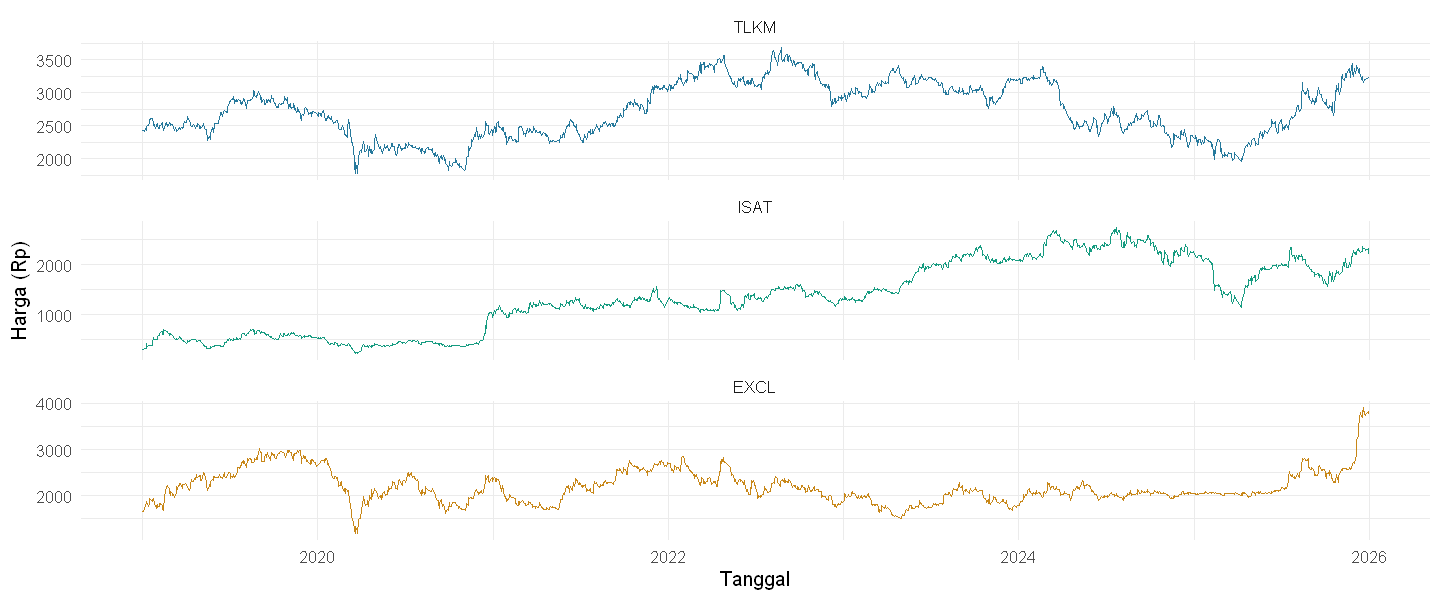

In [133]:
ggplot(long_series(prices), aes(Tanggal, Nilai, color = Saham)) +
    geom_line(linewidth = 0.4) +
    facet_wrap(~Saham, ncol = 1, scales = "free_y") +
    scale_color_manual(values = COLORS) +
    labs(x = "Tanggal", y = "Harga (Rp)") +
    theme(legend.position = "none")

### 3.3. Perbandingan Harga dengan Indeks Awal 100

Harga dinormalisasi menjadi 100 pada tanggal awal bersama agar perubahan relatif antarseri dapat dibandingkan. Nilai indeks 150 berarti harga meningkat 50% dari titik awal. Pengindeksan ini hanya menyamakan skala grafik dan tidak mengubah data harga untuk perhitungan return. Grafik ini bukan simulasi portofolio berbobot.

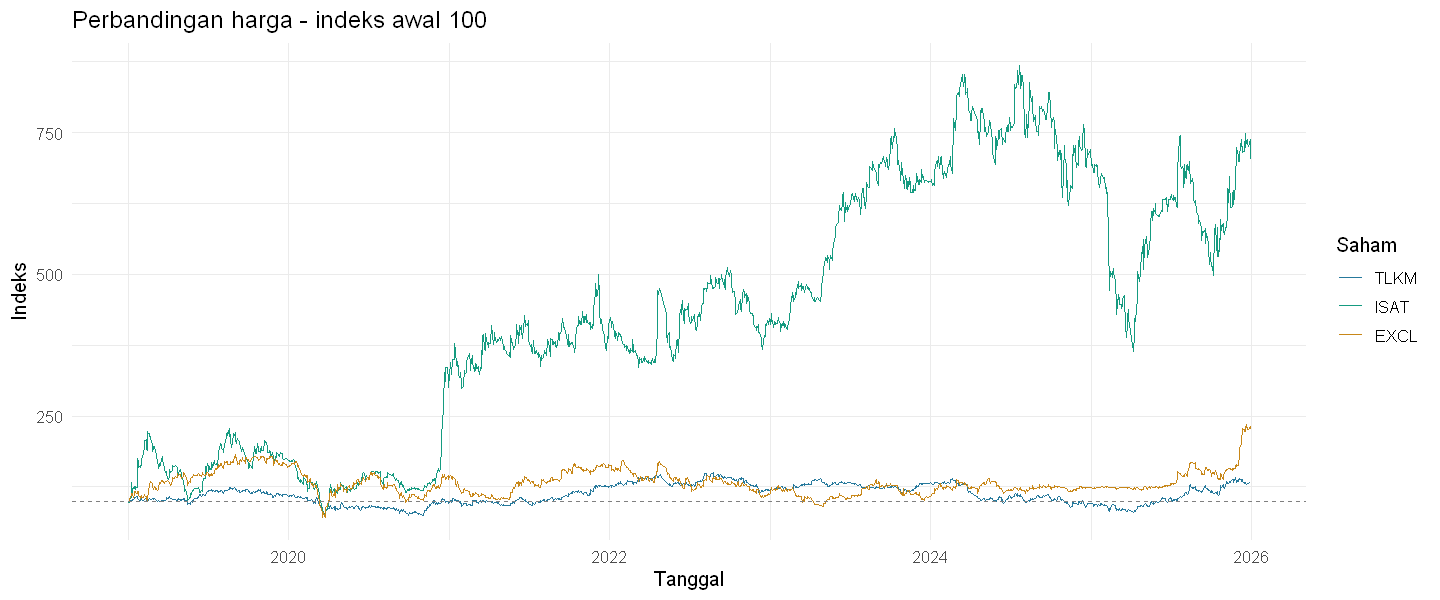

In [134]:
normalized_prices <- prices
normalized_prices[] <- sweep(coredata(prices), 2, as.numeric(prices[1, ]), "/") * 100
ggplot(long_series(normalized_prices), aes(Tanggal, Nilai, color = Saham)) +
    geom_line(linewidth = 0.5) +
    geom_hline(yintercept = 100, linetype = "dashed", color = "grey50") +
    scale_color_manual(values = COLORS) +
    labs(title = "Perbandingan harga - indeks awal 100", x = "Tanggal", y = "Indeks")

### 3.4. Volume Perdagangan

Volume menggambarkan aktivitas perdagangan dalam juta saham. Lonjakan volume dapat menjadi konteks pemeriksaan pergerakan harga, tetapi analisis ini tidak menguji hubungan sebab akibat antara volume dan risiko.

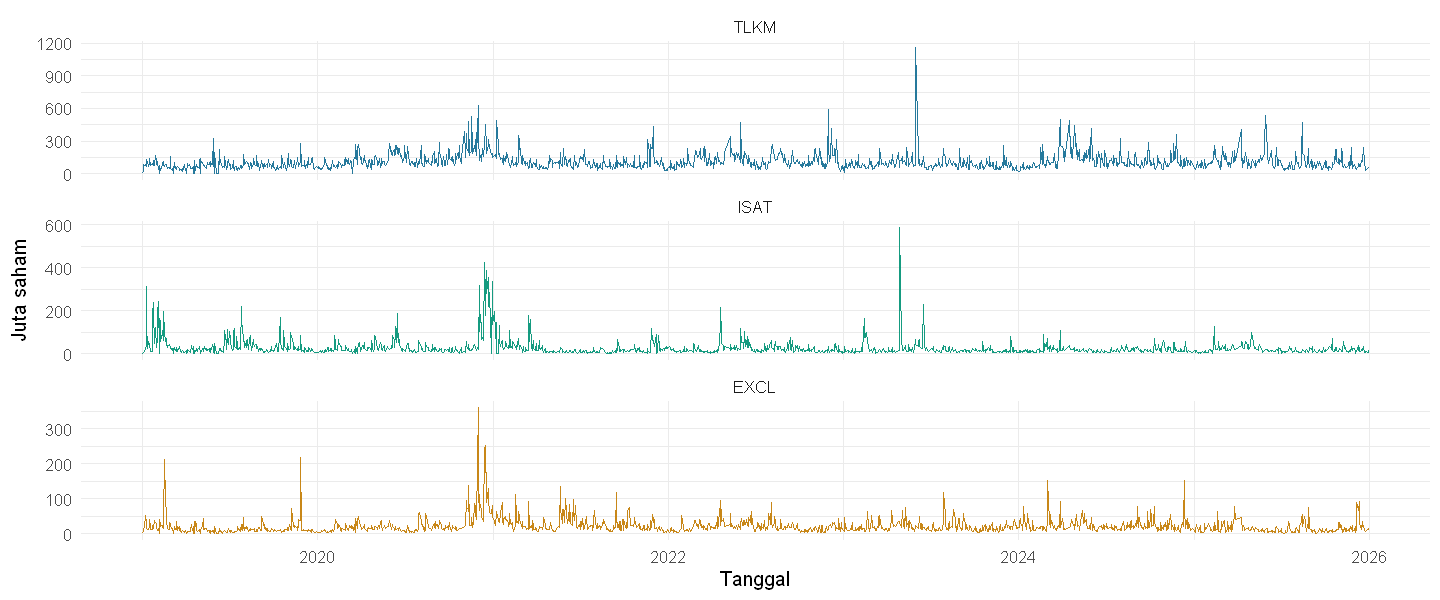

In [135]:
ggplot(long_series(volume), aes(Tanggal, Nilai / 1e6, color = Saham)) +
    geom_line(linewidth = 0.3) +
    facet_wrap(~Saham, ncol = 1, scales = "free_y") +
    scale_color_manual(values = COLORS) +
    labs(x = "Tanggal", y = "Juta saham") +
    theme(legend.position = "none")

## 4. Perhitungan Simple Return
### 4.1. Simple Return Harian

Analisis ini menggunakan **simple return** atau arithmetic return:

$$r_t=\frac{P_t-P_{t-1}}{P_{t-1}}=\frac{P_t}{P_{t-1}}-1.$$

Notasi $P_t$ menyatakan harga saham pada waktu ke-$t$ dari kolom `Adj Close`. Return positif menunjukkan kenaikan harga, sedangkan return negatif menunjukkan penurunan. Return dihitung dari dua hari perdagangan berurutan. `Adj Close` mencakup penyesuaian aksi korporasi yang disediakan Yahoo Finance. Return dihitung dengan `quantmod::ROC(type = "discrete")`.

Rujukan: [Materi 02: Investasi, Pasar Modal, dan Return](../../Materi/menrisk02%20-%20Investasi%2C%20Pasar%20Modal%2C%20dan%20Return.pdf), bagian *Arithmetic Return*.


In [136]:
# Return diskrit harian: Rt = (Pt - Pt-1) / Pt-1 ; Loss = -Rt
simple_returns_all <- na.omit(ROC(prices, type = "discrete"))
data.frame(Saham = SAHAM, `Jumlah harga` = nrow(prices),
           `Jumlah simple return sebelum pembersihan` = nrow(simple_returns_all),
           check.names = FALSE)

Saham,Jumlah harga,Jumlah simple return sebelum pembersihan
<chr>,<int>,<int>
TLKM,1704,1703
ISAT,1704,1703
EXCL,1704,1703


### 4.2. Pemeriksaan dan Pembuangan Return Nol Bersamaan

Tanggal ketika return ketiga saham sama dengan nol ditampilkan bersama volumenya. Mengikuti kode acuan, hari-hari tersebut dibuang bila `HAPUS_HARI_NOL` bernilai `TRUE`. Seluruh analisis berikutnya memakai `simple_returns` hasil pembersihan ini.

In [137]:
semua_nol <- rowSums(coredata(simple_returns_all) == 0) == ncol(simple_returns_all)
all_zero_return_dates <- as.Date(index(simple_returns_all))[semua_nol]
zero_return_check <- data.frame(
    Tanggal = all_zero_return_dates,
    Volume_TLKM = as.numeric(volume[as.character(all_zero_return_dates), "TLKM"]),
    Volume_ISAT = as.numeric(volume[as.character(all_zero_return_dates), "ISAT"]),
    Volume_EXCL = as.numeric(volume[as.character(all_zero_return_dates), "EXCL"])
)

simple_returns <- if (HAPUS_HARI_NOL) simple_returns_all[!semua_nol, ] else simple_returns_all
return_dates <- as.Date(index(simple_returns))
cat("Hari dengan return nol di ketiga saham", ifelse(HAPUS_HARI_NOL, "dibuang:", "ditemukan (tidak dibuang):"),
    sum(semua_nol), "hari\n")

zero_return_check
data.frame(Saham = SAHAM, `Jumlah simple return` = nrow(simple_returns), check.names = FALSE)
head(data.frame(Tanggal = return_dates, coredata(simple_returns)), 10)
tail(data.frame(Tanggal = return_dates, coredata(simple_returns)))

Hari dengan return nol di ketiga saham dibuang: 13 hari


Tanggal,Volume_TLKM,Volume_ISAT,Volume_EXCL
<date>,<dbl>,<dbl>,<dbl>
2019-02-05,0,0,0
2019-03-07,0,0,0
2019-04-03,0,0,0
2019-04-17,0,0,0
2019-04-19,0,0,0
2019-05-01,0,0,0
2019-05-30,0,0,0
2019-06-03,0,0,0
2019-06-04,0,0,0


Saham,Jumlah simple return
<chr>,<int>
TLKM,1690
ISAT,1690
EXCL,1690


,Tanggal,TLKM,ISAT,EXCL
,<date>,<dbl>,<dbl>,<dbl>
1,2019-01-02,-0.005333411,-0.023738654,0.000000000
2,2019-01-03,0.002680853,0.003039386,0.020202045
3,2019-01-04,-0.008021257,0.045454518,0.009901038
4,2019-01-07,0.016172438,0.023188380,0.049019628
5,2019-01-08,0.007957427,0.022662865,0.023364393
6,2019-01-09,-0.018420879,0.246537473,0.027397260
7,2019-01-10,0.018766576,-0.135555530,0.000000000
8,2019-01-11,0.015789509,0.015424189,-0.022222201
9,2019-01-14,-0.002590566,0.063291044,-0.040909156


,Tanggal,TLKM,ISAT,EXCL
,<date>,<dbl>,<dbl>,<dbl>
1685,2025-12-19,-0.014450841,0.016736458,0.056910569
1686,2025-12-22,0.017595292,0.004115266,-0.035897436
1687,2025-12-23,0.000000000,-0.008196800,-0.005319149
1688,2025-12-24,-0.002881854,-0.008264437,0.002673797
1689,2025-12-29,0.008670551,0.016666722,0.021333333
1690,2025-12-30,-0.002865339,-0.049180383,-0.020887728


### 4.3. Contoh Perhitungan Simple Return

Contoh berikut menampilkan perubahan harga relatif antara dua hari perdagangan berurutan. Return dikalikan 100 untuk ditampilkan dalam persen.


In [138]:
saham_contoh <- "TLKM"
previous_price <- as.numeric(prices[1, saham_contoh])
current_price <- as.numeric(prices[2, saham_contoh])
example_return <- current_price / previous_price - 1
data.frame(Saham = saham_contoh,
    `Tanggal sebelumnya` = as.Date(index(prices)[1]), Tanggal = as.Date(index(prices)[2]),
    `Harga sebelumnya` = previous_price, `Harga saat ini` = current_price,
    `Simple return` = example_return, `Simple return (%)` = 100 * example_return,
    check.names = FALSE)


Saham,Tanggal sebelumnya,Tanggal,Harga sebelumnya,Harga saat ini,Simple return,Simple return (%)
<chr>,<date>,<date>,<dbl>,<dbl>,<dbl>,<dbl>
TLKM,2019-01-01,2019-01-02,2436.687,2423.691,-0.005333411,-0.5333411


### 4.4. Statistik Deskriptif Simple Return

Statistik berikut dihitung pada periode training 2019-2024, mengikuti kode acuan. Skewness dan kurtosis memakai fungsi paket `moments`; kurtosis dilaporkan dalam bentuk biasa, dengan nilai normal sebesar 3. Rata-rata simple return merupakan expected return historis harian.

### Interpretasi Statistik Return

Tabel berikut merangkum simple return training 2019-2024, termasuk jumlah observasi dengan return nol. Grafik EDA pada bagian sebelumnya dan berikutnya tetap mencakup seluruh periode 2019-2025.

In [139]:
returns_training <- simple_returns[paste0("/", TRAIN_END)]
return_summary <- data.frame(
    Saham = SAHAM,
    N = nrow(returns_training),
    Mean = round(colMeans(returns_training), 6),
    Variance = round(apply(returns_training, 2, var), 6),
    Min = round(apply(returns_training, 2, min), 4),
    Max = round(apply(returns_training, 2, max), 4),
    Skewness = round(apply(returns_training, 2, moments::skewness), 3),
    Kurtosis = round(apply(returns_training, 2, moments::kurtosis), 3),
    Zero_Ret = colSums(returns_training == 0),
    check.names = FALSE, row.names = NULL
)
return_summary

Saham,N,Mean,Variance,Min,Max,Skewness,Kurtosis,Zero_Ret
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
TLKM,1454,0.000135,0.000337,-0.0696,0.1374,0.616,7.635,120
ISAT,1454,0.001946,0.001217,-0.1356,0.2478,1.725,11.958,114
EXCL,1454,0.000481,0.000687,-0.0925,0.2482,1.202,10.902,153


## 5. Eksplorasi Data Simple Return
### 5.1. Pergerakan Simple Return Harian

Bagian 5.1-5.5 memakai return periode training 2019-2024, sesuai kode acuan; bagian 5.6-5.9 memakai seluruh periode 2019-2025 sebagai konteks tambahan.

Grafik return memusatkan perhatian pada perubahan harian. Pengelompokan fluktuasi besar dan kecil menunjukkan alasan untuk berhati-hati terhadap asumsi distribusi serta volatilitas yang tetap sepanjang waktu.

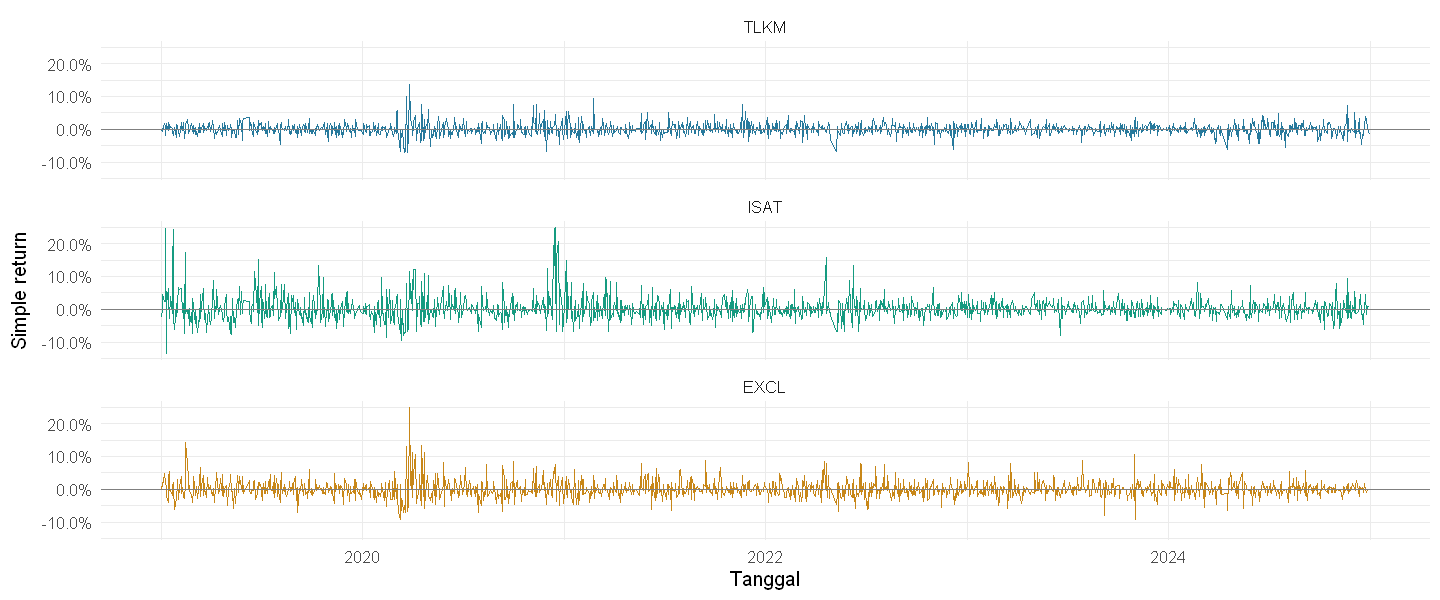

In [140]:
ggplot(long_series(returns_training), aes(Tanggal, Nilai, color = Saham)) +
    geom_line(linewidth = 0.3) + geom_hline(yintercept = 0, color = "grey50") +
    facet_wrap(~Saham, ncol = 1) + scale_color_manual(values = COLORS) +
    scale_y_continuous(labels = percent) +
    labs(x = "Tanggal", y = "Simple return") + theme(legend.position = "none")

### 5.2. Histogram dan Distribusi Normal Pembanding

Histogram dibandingkan dengan fungsi kerapatan probabilitas normal yang memakai rata-rata dan standar deviasi sampel yang sama. Perbedaan pada ekor menjadi bahan eksplorasi untuk pemodelan kejadian ekstrem. Perbandingan visual ini bukan uji formal dan tidak membuktikan kesesuaian model GEV.

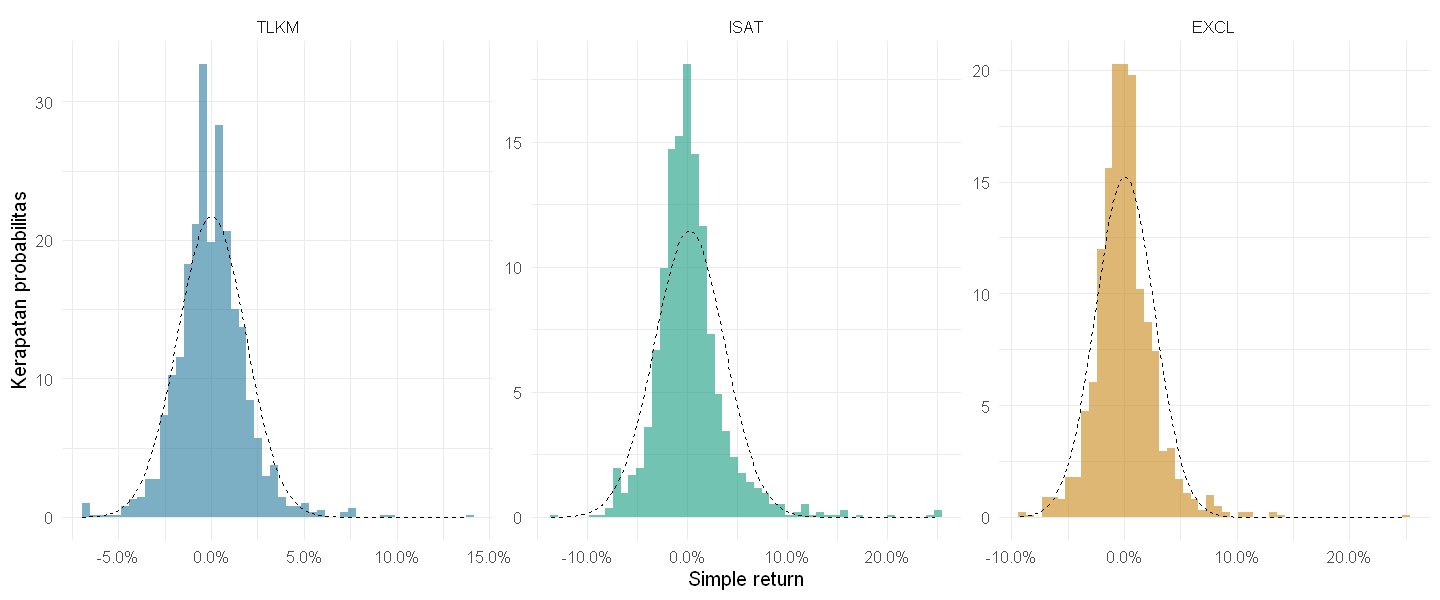

In [141]:
normal_curves <- data.frame()
for (saham in SAHAM) {
    x <- as.numeric(returns_training[, saham])
    grid <- seq(min(x), max(x), length.out = 400)
    curve <- data.frame(Saham = saham, Nilai = grid, Densitas = dnorm(grid, mean(x), sd(x)))
    normal_curves <- rbind(normal_curves, curve)
}
normal_curves$Saham <- factor(normal_curves$Saham, levels = SAHAM)

ggplot(long_series(returns_training), aes(Nilai)) +
    geom_histogram(aes(y = after_stat(density), fill = Saham), bins = 50, alpha = 0.6) +
    geom_line(data = normal_curves, aes(y = Densitas), linetype = "dashed") +
    facet_wrap(~Saham, scales = "free") + scale_fill_manual(values = COLORS) +
    scale_x_continuous(labels = percent) +
    labs(x = "Simple return", y = "Kerapatan probabilitas") + theme(legend.position = "none")

### 5.3. Boxplot Simple Return

Boxplot merangkum median, rentang antarkuartil, dan observasi jauh dari pusat data. Titik ekstrem dipertahankan karena justru relevan untuk analisis EVT; tidak dilakukan winsorization maupun penghapusan berdasarkan besarnya return.

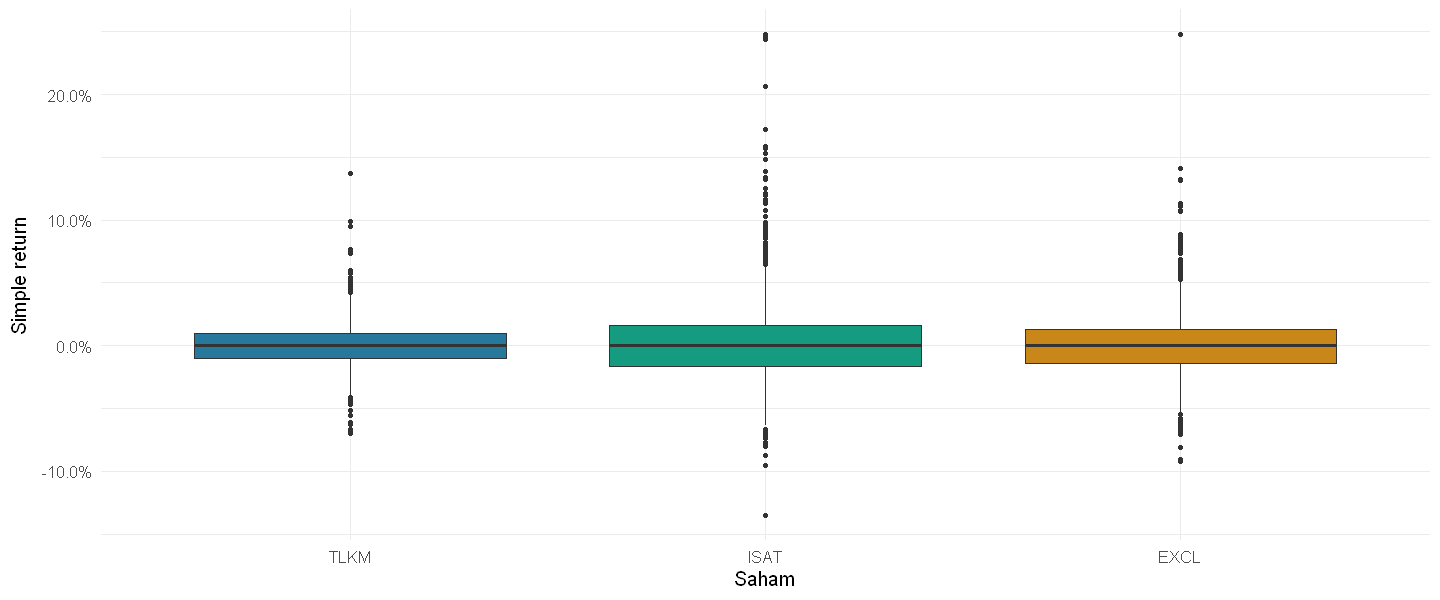

In [142]:
ggplot(long_series(returns_training), aes(Saham, Nilai, fill = Saham)) +
    geom_boxplot(outlier.size = 1) + scale_fill_manual(values = COLORS) +
    scale_y_continuous(labels = percent) +
    labs(x = "Saham", y = "Simple return") + theme(legend.position = "none")

### 5.4. Q-Q Plot terhadap Distribusi Normal

Q–Q plot membandingkan kuantil empiris dengan kuantil normal. Penyimpangan sistematis pada bagian ujung membantu menilai keterbatasan pendekatan normal secara visual. GEV nantinya diestimasi dari maksimum kerugian per blok, bukan dari keseluruhan return harian.

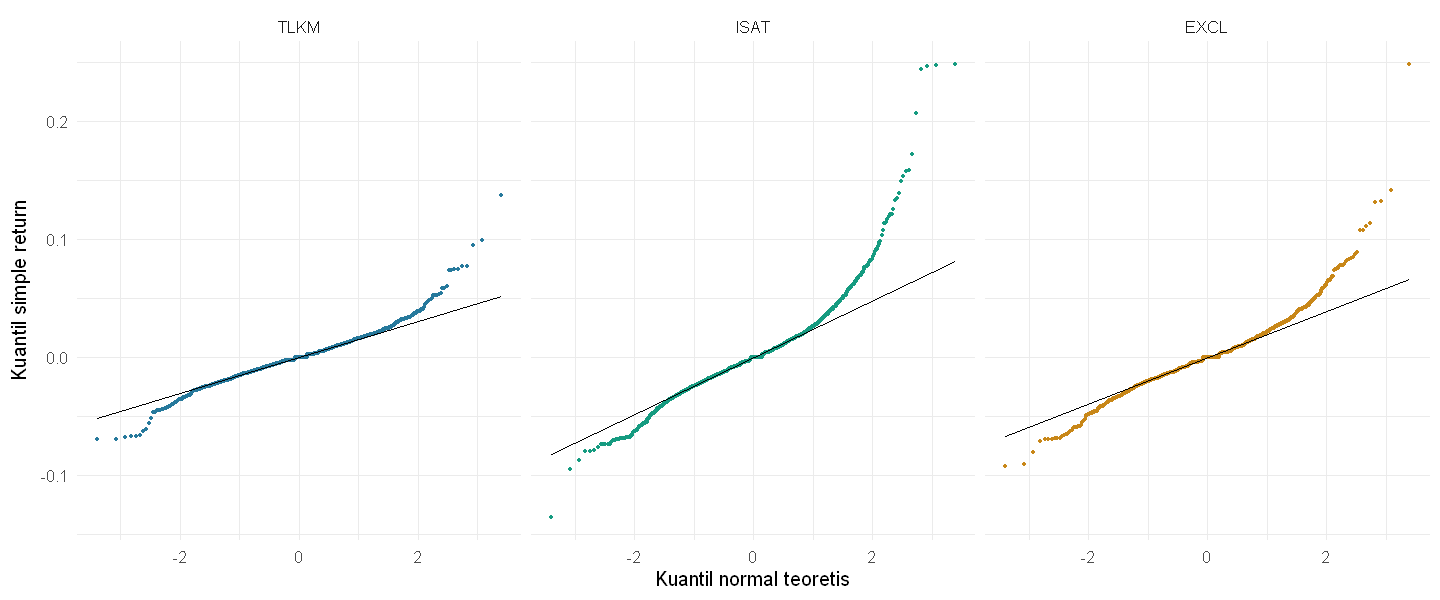

In [143]:
ggplot(long_series(returns_training), aes(sample = Nilai, color = Saham)) +
    stat_qq(size = 0.8) + stat_qq_line(color = "black") +
    facet_wrap(~Saham) + scale_color_manual(values = COLORS) +
    labs(x = "Kuantil normal teoretis", y = "Kuantil simple return") +
    theme(legend.position = "none")

### 5.5. Pemeriksaan Normalitas Return secara Formal

Karakteristik Simple Return periode estimasi 2019–2024 diperiksa dengan uji Jarque–Bera (acuan keputusan normalitas), uji Ljung–Box lag 10 pada return (autokorelasi) dan kuadrat return (volatility clustering), serta uji Kolmogorov–Smirnov satu sampel terhadap distribusi normal yang parameternya diisi menggunakan rata-rata dan standar deviasi sampel. Statistik KS mengukur selisih maksimum fungsi distribusi empiris dan teoritis.

Notebook memakai KS standar (`ks.test`) tanpa bootstrap, baik untuk normalitas return maupun uji kesesuaian GEV. P-value KS normalitas juga tidak terkalibrasi karena parameter normal diestimasi dari sampel yang sama, sehingga hasil dibaca sebagai diagnostik kasar. Uji ini juga mengasumsikan observasi independen.

In [144]:
norm_tab <- data.frame()
for (s in SAHAM) {
    r <- as.numeric(returns_training[, s])
    jb  <- moments::jarque.test(r)
    ks  <- suppressWarnings(ks.test(r, "pnorm", mean(r), sd(r)))
    lb1 <- Box.test(r,   lag = 10, type = "Ljung-Box")   # autokorelasi return
    lb2 <- Box.test(r^2, lag = 10, type = "Ljung-Box")   # volatility clustering
    norm_tab <- rbind(norm_tab, data.frame(
        Saham      = s,
        JB_pvalue  = format.pval(jb$p.value, digits = 3),
        KS_pvalue  = format.pval(ks$p.value, digits = 3),
        LB_ret_p   = format.pval(lb1$p.value, digits = 3),
        LB_ret2_p  = format.pval(lb2$p.value, digits = 3),
        Normalitas = ifelse(jb$p.value < SIGNIFICANCE, "Tolak H0 (tidak normal)", "Normal")
    ))
}
norm_tab

Saham,JB_pvalue,KS_pvalue,LB_ret_p,LB_ret2_p,Normalitas
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
TLKM,<2e-16,7.2e-05,7.85e-07,<2e-16,Tolak H0 (tidak normal)
ISAT,<2e-16,5.16e-14,0.00463,<2e-16,Tolak H0 (tidak normal)
EXCL,<2e-16,7.48e-10,3.58e-06,<2e-16,Tolak H0 (tidak normal)


### Interpretasi Pemeriksaan Normalitas

Output menampilkan statistik dan p-value KS biasa. Karena parameter normal diperkirakan dari sampel yang sama, p-value ini tidak terkoreksi untuk estimasi parameter; baca sebagai diagnostik kasar. Ketergantungan antarhari juga tidak diperhitungkan. LB_ret2_p < 0,05 menunjukkan volatility clustering, sehingga asumsi maksima i.i.d. perlu dicermati.


### 5.6. Korelasi Simple Return

Korelasi Pearson dihitung pada tanggal yang lengkap untuk ketiga saham. Korelasi menggambarkan hubungan linear historis dan tidak langsung mengukur dependensi kejadian ekstrem. Nilai ini bersifat deskriptif karena analisis VaR dilakukan per saham.

,TLKM,ISAT,EXCL
TLKM,1.0000000,0.2938549,0.3774307
ISAT,0.2938549,1.0000000,0.3941778
EXCL,0.3774307,0.3941778,1.0000000


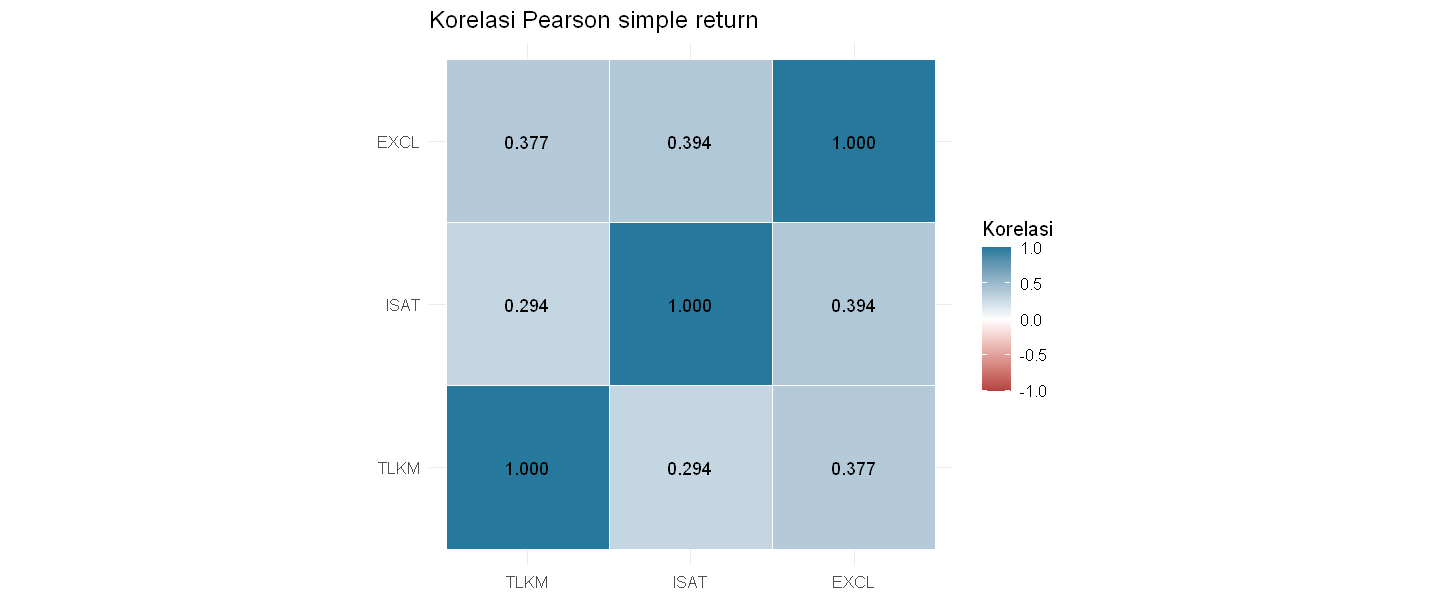

In [145]:
correlation <- cor(coredata(simple_returns))
correlation
correlation_long <- as.data.frame(as.table(correlation))
names(correlation_long) <- c("Saham_1", "Saham_2", "Korelasi")
ggplot(correlation_long, aes(Saham_1, Saham_2, fill = Korelasi)) +
    geom_tile(color = "white") + geom_text(aes(label = sprintf("%.3f", Korelasi))) +
    scale_fill_gradient2(low = "#b44040", mid = "white", high = "#26799c", limits = c(-1, 1)) +
    coord_equal() + labs(x = NULL, y = NULL, title = "Korelasi Pearson simple return")

### 5.7. Volatilitas Return dengan Rolling Window 21 Hari Perdagangan

Standar deviasi dihitung pada jendela bergulir 21 observasi perdagangan. Angka pada grafik adalah volatilitas harian dalam jendela tersebut dan tidak dianualisasi. Perubahan volatilitas menjadi keterbatasan penting bagi VaR statis yang digunakan dalam backtesting.

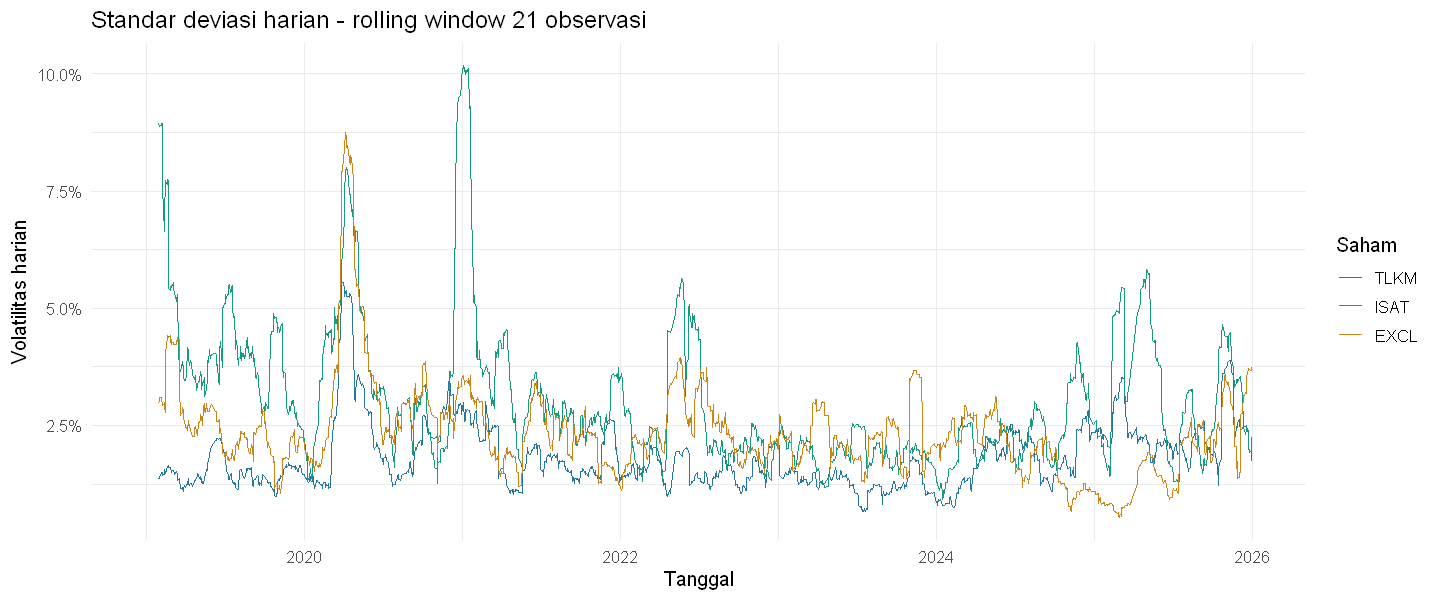

In [146]:
rolling_volatility <- zoo::rollapplyr(simple_returns, WINDOW, sd, fill = NA, by.column = TRUE)
ggplot(long_series(rolling_volatility), aes(Tanggal, Nilai, color = Saham)) +
    geom_line(linewidth = 0.5, na.rm = TRUE) + scale_color_manual(values = COLORS) +
    scale_y_continuous(labels = percent) +
    labs(title = "Standar deviasi harian - rolling window 21 observasi", x = "Tanggal", y = "Volatilitas harian")

### 5.8. Statistik Simple Return per Tahun

Ringkasan tahunan memperlihatkan perubahan rata-rata dan penyebaran return antarperiode. Variansi tetap dihitung dari return harian di masing-masing tahun, sehingga tidak boleh dibaca sebagai variansi return investasi satu tahun.

In [147]:
annual_summary <- long_series(simple_returns) |>
    mutate(Tahun = as.integer(format(Tanggal, "%Y"))) |>
    group_by(Tahun, Saham) |>
    summarise(N = n(), Mean = mean(Nilai), Variansi = var(Nilai), Std = sd(Nilai),
              Minimum = min(Nilai), Maksimum = max(Nilai), .groups = "drop")
annual_summary

Tahun,Saham,N,Mean,Variansi,Std,Minimum,Maksimum
<int>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2019,TLKM,244,5.108592e-04,0.0002140192,0.01462939,-0.04672904,0.03589738
2019,ISAT,244,3.278561e-03,0.0021815261,0.04670681,-0.13555553,0.24653747
2019,EXCL,244,2.213739e-03,0.0006288877,0.02507763,-0.07102274,0.14146346
2020,TLKM,242,-1.977080e-04,0.0007097031,0.02664025,-0.06962023,0.13740458
2020,ISAT,242,3.383814e-03,0.0023328574,0.04829966,-0.09498695,0.24778741
2020,EXCL,242,1.566136e-04,0.0014912178,0.03861629,-0.09090903,0.24822689
2021,TLKM,247,1.174448e-03,0.0003421373,0.01849695,-0.04142011,0.09463720
2021,ISAT,247,1.785249e-03,0.0010556631,0.03249097,-0.06953640,0.14851484
2021,EXCL,247,9.189954e-04,0.0005091021,0.02256329,-0.06513416,0.08856104


### 5.9. Observasi dengan Simple Return Terendah

Sepuluh simple return terendah setiap saham ditampilkan untuk mengidentifikasi tanggal kerugian relatif terbesar. Observasi tersebut perlu ditinjau bersama aksi korporasi dan kualitas data. Nilai ekstrem yang valid tetap dipakai dalam pemodelan.

In [148]:
extreme_negative_returns <- long_series(simple_returns) |>
    group_by(Saham) |>
    slice_min(Nilai, n = 10, with_ties = FALSE) |>
    ungroup() |>
    mutate(`Simple return (%)` = 100 * Nilai) |>
    rename(`Simple return` = Nilai)
extreme_negative_returns

Tanggal,Saham,Simple return,Simple return (%)
<date>,<fct>,<dbl>,<dbl>
2020-03-17,TLKM,-0.06962023,-6.962023
2020-03-23,TLKM,-0.06944449,-6.944449
2020-03-19,TLKM,-0.06761556,-6.761556
2022-05-09,TLKM,-0.06709949,-6.709949
2020-03-09,TLKM,-0.06666675,-6.666675
2020-11-30,TLKM,-0.06647392,-6.647392
2022-12-06,TLKM,-0.06250010,-6.250010
2024-04-16,TLKM,-0.06122450,-6.122450
2025-02-10,TLKM,-0.05791504,-5.791504


## 6. Metode Estimasi Value at Risk
### 6.1. Konsep VaR dan Pendekatan Block Maxima

Value at Risk (VaR) mengestimasi kuantil kerugian pada tingkat kepercayaan dan jangka waktu tertentu. Analisis memakai tingkat kepercayaan $c=95\%$ dan $99\%$, dengan horizon satu hari perdagangan untuk setiap saham. Kerugian simple didefinisikan $L_t=-r_t$.

Block Maxima membagi kerugian berurutan menjadi blok tidak tumpang tindih. Tiap blok memiliki $m=5$ observasi dan menyumbang satu maksimum:

$$M_j=\max(L_{(j-1)m+1},\ldots,L_{jm}).$$

Blok terakhir yang tidak lengkap dikeluarkan. Pendekatan BM–GEV merujuk pada [Najamuddin dkk. (2024)](https://doi.org/10.30598/barekengvol18iss2pp0695-0706).


### 6.2. Distribusi GEV dan Konversi VaR Harian

Distribusi GEV memodelkan maksimum kerugian blok. Parameter lokasi, skala positif, dan bentuk diestimasi dengan MLE menggunakan `evd::fgev`.

Dengan asumsi kerugian harian independen dan identik, $G_m(x)=F_L(x)^m$. Karena $F_L(q_c)=c$, VaR harian diperoleh dari:

$$q_c=G_m^{-1}(c^m).$$

$q_c$ langsung menyatakan fraksi kerugian simple, sehingga tidak memerlukan konversi eksponensial. Kuantil GEV pada probabilitas $c$ adalah kuantil maksimum blok, bukan VaR harian. Asumsi independensi dan panjang blok membatasi interpretasi.


### 6.3. VaR Persentase dan Rupiah

Kerugian simple $q_c$ langsung menyatakan fraksi kehilangan nilai investasi:

$$\operatorname{VaR}_{c,\%}=100q_c,\qquad \operatorname{VaR}_{c,\mathrm{Rp}}=V_0q_c.$$

Nilai $V_0$ ditetapkan Rp1.000.000.000 untuk setiap saham secara individual. VaR bukan batas kerugian absolut.


In [149]:
# Block maxima dari LOSS (ekor kerugian); blok akhir yang tidak penuh dibuang.
block_maxima <- function(loss, m) {
    nb <- floor(length(loss) / m)
    apply(matrix(loss[1:(nb * m)], nrow = m), 2, max)
}

# Estimasi GEV (MLE) memakai evd::fgev; retry tanpa Hessian bila SE gagal dihitung.
fit_gev <- function(bm) {
    fit <- tryCatch(evd::fgev(bm, std.err = TRUE), error = function(e) NULL)
    if (is.null(fit)) fit <- evd::fgev(bm, std.err = FALSE)
    fit
}

# VaR harian dari GEV blok:
# P(loss harian <= VaR) = level  =>  P(max blok <= VaR) = level^m
var_gev <- function(par, m, level) {
    evd::qgev(level^m, loc = par[["loc"]], scale = par[["scale"]], shape = par[["shape"]])
}

# Backtesting: Kupiec (POF), Christoffersen (independensi), Conditional Coverage
xlogy <- function(a, b) ifelse(a == 0, 0, a * log(b))

backtest <- function(loss_test, var_vec, level) {
    p    <- 1 - level
    hits <- as.integer(loss_test > var_vec)     # pelanggaran: loss aktual > VaR
    N    <- length(hits); x <- sum(hits); pi_hat <- x / N

    # Kupiec POF
    LR_pof <- -2 * ((xlogy(N - x, 1 - p) + xlogy(x, p)) -
                    (xlogy(N - x, 1 - pi_hat) + xlogy(x, pi_hat)))

    # Christoffersen independensi
    n00 <- sum(hits[-N] == 0 & hits[-1] == 0); n01 <- sum(hits[-N] == 0 & hits[-1] == 1)
    n10 <- sum(hits[-N] == 1 & hits[-1] == 0); n11 <- sum(hits[-N] == 1 & hits[-1] == 1)
    pi01 <- ifelse(n00 + n01 > 0, n01 / (n00 + n01), 0)
    pi11 <- ifelse(n10 + n11 > 0, n11 / (n10 + n11), 0)
    pi_  <- (n01 + n11) / (n00 + n01 + n10 + n11)
    ll_ind <- xlogy(n00 + n10, 1 - pi_) + xlogy(n01 + n11, pi_)
    ll_mkv <- xlogy(n00, 1 - pi01) + xlogy(n01, pi01) + xlogy(n10, 1 - pi11) + xlogy(n11, pi11)
    LR_ind <- max(0, -2 * (ll_ind - ll_mkv))
    LR_cc  <- LR_pof + LR_ind

    p_pof <- 1 - pchisq(LR_pof, 1)
    p_ind <- 1 - pchisq(LR_ind, 1)
    p_cc  <- 1 - pchisq(LR_cc, 2)

    data.frame(
        N_test     = N,
        Failure    = x,
        Expected   = round(N * p, 1),
        Fail_Rate  = round(pi_hat, 4),
        Kupiec_LR  = round(LR_pof, 3), Kupiec_p = round(p_pof, 4),
        Christ_LR  = round(LR_ind, 3), Christ_p = round(p_ind, 4),
        CC_LR      = round(LR_cc, 3),  CC_p     = round(p_cc, 4),
        Kesimpulan = ifelse(p_cc > SIGNIFICANCE, "Valid", "Tidak valid")
    )
}

## 7. Estimasi Value at Risk dan Interpretasi
### 7.1. Rancangan Estimasi dan Pengujian

Model diestimasi menggunakan return 2019–2024, kemudian VaR dipertahankan tetap selama pengujian tahun 2025. Pemisahan ini mencegah data pengujian dipakai untuk menentukan parameter model. Tingkat kepercayaan, panjang blok, dan signifikansi uji ditetapkan pada bagian parameter. Statistik deskriptif return dan uji karakteristik data memakai periode training; seluruh data 2019–2025 hanya dipakai untuk eksplorasi tambahan.

Return pada hari perdagangan pertama tahun 2025 memakai harga penutupan sebelumnya yang tersedia sebagai pembanding.


In [150]:
train_returns <- simple_returns[paste0("/", TRAIN_END)]
test_returns <- simple_returns[paste0(TEST_START, "/", TEST_END)]
train_losses <- -train_returns
test_losses <- -test_returns
split_summary <- data.frame(
    Periode = c("Estimasi", "Backtesting"),
    `Awal return` = as.Date(c(index(train_returns)[1], index(test_returns)[1])),
    `Akhir return` = as.Date(c(tail(index(train_returns), 1), tail(index(test_returns), 1))),
    `N return per saham` = c(nrow(train_returns), nrow(test_returns)), check.names = FALSE
)
split_summary

Periode,Awal return,Akhir return,N return per saham
<chr>,<date>,<date>,<int>
Estimasi,2019-01-02,2024-12-30,1454
Backtesting,2025-01-02,2025-12-30,236


### 7.2. Maksimum Blok, Estimasi GEV, dan Uji Gumbel

Maksimum kerugian diambil dari blok lengkap berukuran lima hari pada periode estimasi. Parameter lokasi, skala, dan bentuk diestimasi dengan MLE melalui `evd::fgev`. Uji rasio likelihood membandingkan GEV dengan model Gumbel yang menetapkan parameter bentuk $\xi=0$.

In [151]:
param_tab <- data.frame()
fits <- list()

for (s in SAHAM) {
    loss_tr <- as.numeric(train_losses[, s])
    bm      <- block_maxima(loss_tr, BLOCK_SIZE)
    ft      <- fit_gev(bm)
    par     <- ft$estimate
    fits[[s]] <- list(bm = bm, fit = ft)

    se <- if (!is.null(ft$std.err)) ft$std.err else c(loc = NA, scale = NA, shape = NA)
    xi_lo <- par[["shape"]] - 1.96 * se[["shape"]]
    xi_hi <- par[["shape"]] + 1.96 * se[["shape"]]

    # LR test: Gumbel (xi = 0) vs GEV
    ft0  <- tryCatch(evd::fgev(bm, shape = 0, std.err = FALSE), error = function(e) NULL)
    lr_p <- if (!is.null(ft0)) 1 - pchisq(ft0$deviance - ft$deviance, df = 1) else NA

    param_tab <- rbind(param_tab, data.frame(
        Saham = s, Jml_Blok = length(bm),
        Location = round(par[["loc"]], 5), Scale = round(par[["scale"]], 5),
        Shape = round(par[["shape"]], 4),
        Shape_CI95 = sprintf("[%.3f ; %.3f]", xi_lo, xi_hi),
        LR_Gumbel_p = round(lr_p, 4),
        Tipe_Ekor = ifelse(!is.na(xi_lo) && xi_lo > 0, "Heavy tail (Frechet)",
                    ifelse(!is.na(xi_hi) && xi_hi < 0, "Ekor pendek (Weibull)",
                           "xi tidak signifikan beda dari 0")),
        Konvergensi = ft$convergence
    ))
}
param_tab

Saham,Jml_Blok,Location,Scale,Shape,Shape_CI95,LR_Gumbel_p,Tipe_Ekor,Konvergensi
<chr>,<int>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<chr>
TLKM,290,0.01361,0.00996,-0.0053,[-0.070 ; 0.060],0.8925,xi tidak signifikan beda dari 0,successful
ISAT,290,0.02092,0.01518,0.0381,[-0.048 ; 0.124],0.3637,xi tidak signifikan beda dari 0,successful
EXCL,290,0.01823,0.01307,0.0000,[-0.084 ; 0.084],0.9960,xi tidak signifikan beda dari 0,successful


### 7.3. Diagnostik Visual GEV

Plot diagnostik dibuat memakai `extRemes::fevd()` dan `plot()`, mengikuti kode acuan. Plot membantu memeriksa kecocokan GEV pada maksimum kerugian blok secara visual; hasilnya melengkapi uji KS, bukan menggantikannya.

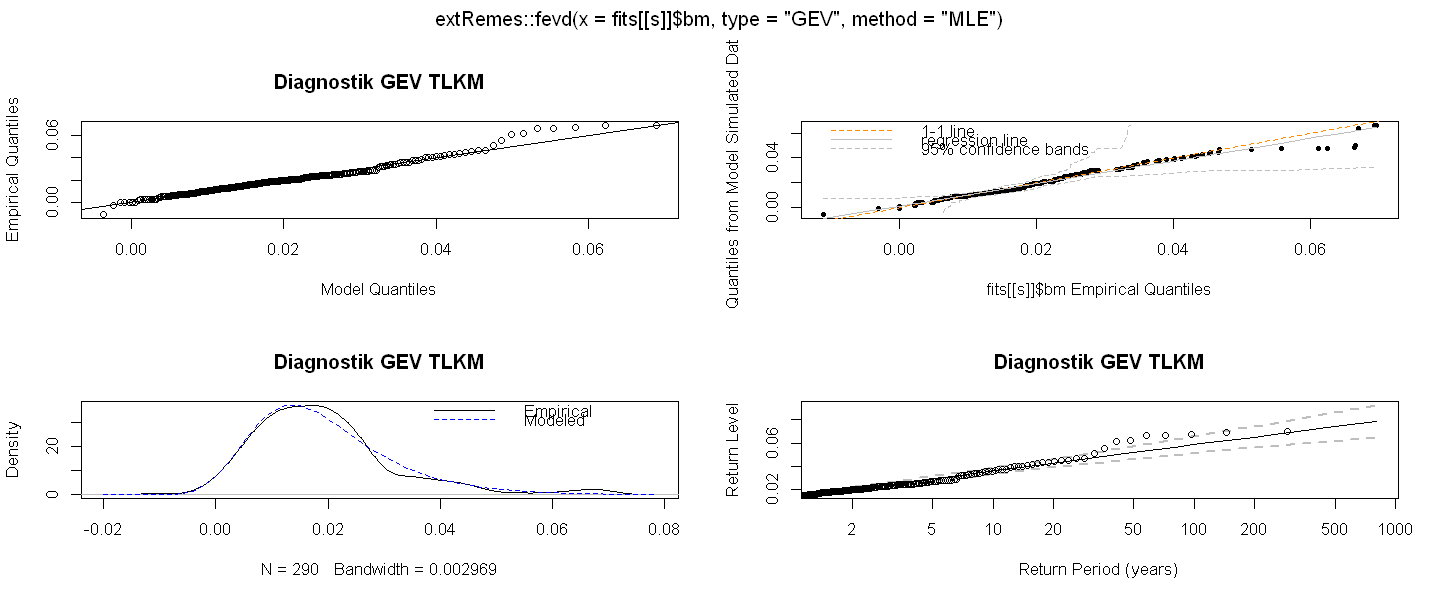

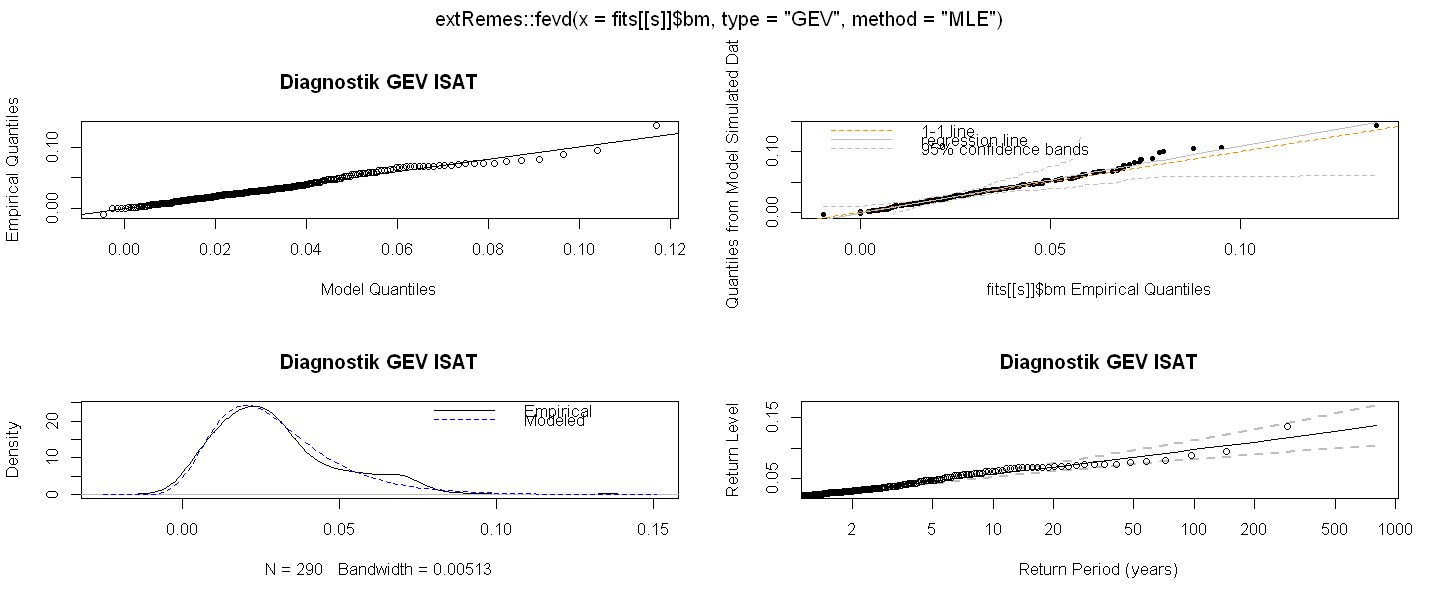

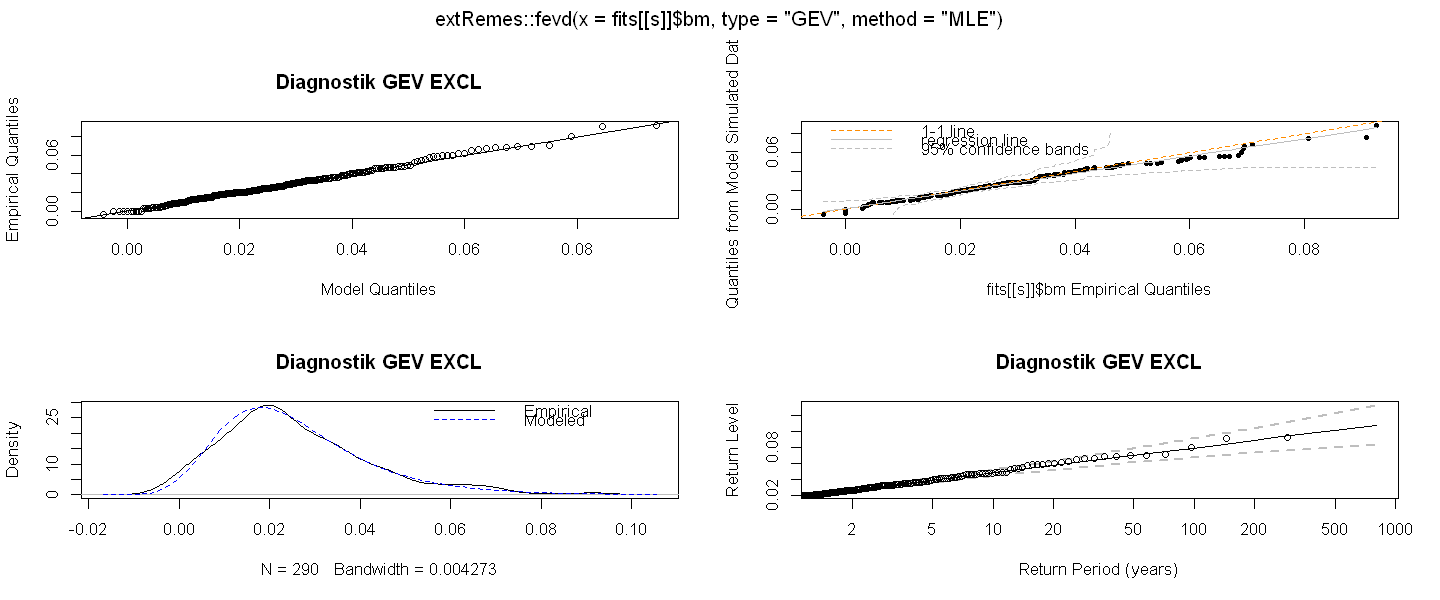

In [152]:
# Latar putih penuh (tidak transparan) untuk semua panel diagnostik
options(repr.plot.bg = "white")

for (s in SAHAM) {
    par(bg = "white")
    diagnostic_fit <- extRemes::fevd(fits[[s]]$bm, type = "GEV", method = "MLE")
    plot(diagnostic_fit, main = paste("Diagnostik GEV", s))
}

### 7.4. Uji Kesesuaian GEV dengan Kolmogorov-Smirnov

Uji KS membandingkan fungsi distribusi empiris maksimum blok kerugian dengan GEV hasil estimasi, memakai `ks.test` standar. Hipotesis nol menyatakan maksimum blok berasal dari GEV terpasang.

Karena parameter GEV diestimasi dari sampel yang sama, p-value KS standar tidak terkalibrasi dan cenderung terlalu longgar, yaitu lebih mudah gagal menolak H0. Hasil dibaca sebagai diagnostik kasar dan dilengkapi plot diagnostik pada bagian 7.3.

In [153]:
gof_tab <- data.frame()
for (s in SAHAM) {
    bm  <- fits[[s]]$bm
    par <- fits[[s]]$fit$estimate
    ks_gev <- suppressWarnings(
        ks.test(bm, function(q) evd::pgev(q, par[["loc"]], par[["scale"]], par[["shape"]])))
    gof_tab <- rbind(gof_tab, data.frame(
        Saham = s,
        D_KS = round(as.numeric(ks_gev$statistic), 4),
        P_Value = round(ks_gev$p.value, 4),
        Keputusan = ifelse(ks_gev$p.value > SIGNIFICANCE, "Terima H0 (sesuai GEV)", "Tolak H0")
    ))
}
gof_tab

Saham,D_KS,P_Value,Keputusan
<chr>,<dbl>,<dbl>,<chr>
TLKM,0.0576,0.2919,Terima H0 (sesuai GEV)
ISAT,0.0350,0.8701,Terima H0 (sesuai GEV)
EXCL,0.0304,0.9515,Terima H0 (sesuai GEV)


### Interpretasi Uji Kesesuaian GEV

Tabel menampilkan statistik KS dan p-value `ks.test`. P-value kecil memberi bukti bahwa maksimum blok kurang sesuai dengan GEV terpasang menurut diagnostik ini. P-value besar berarti H0 belum ditolak, bukan bukti bahwa GEV pasti benar. P-value ini tidak memperhitungkan estimasi parameter dari sampel yang sama. Hasil juga bergantung pada asumsi bahwa maksimum blok dapat diperlakukan sebagai observasi independen dan identik.

### 7.5. VaR Harian pada Tingkat Kepercayaan 95% dan 99%

Tabel output menampilkan VaR harian yang diestimasi dari data 2019–2024 dan digunakan untuk memprediksi kerugian tahun 2025. Persentase serta nilai rupiah dihitung sesuai jenis return yang dipakai notebook.


In [154]:
var_tab <- data.frame()
for (s in SAHAM) {
    par <- fits[[s]]$fit$estimate
    for (lv in CONFIDENCE_LEVELS) {
        v_gev <- var_gev(par, BLOCK_SIZE, lv)
        var_tab <- rbind(var_tab, data.frame(
            Saham = s, Level = lv,
            VaR_BM = round(v_gev, 5),
            Persentase_Risiko = paste0(round(v_gev * 100, 2), "%"),
            Estimasi_Rugi_Rp = format(round(v_gev * INVESTMENT, 0), big.mark = ".", decimal.mark = ",",
                                      scientific = FALSE)
        ))
    }
}
var_tab

Saham,Level,VaR_BM,Persentase_Risiko,Estimasi_Rugi_Rp
<chr>,<dbl>,<dbl>,<chr>,<chr>
TLKM,0.95,0.02712,2.71%,27.117.861
TLKM,0.99,0.04316,4.32%,43.164.955
ISAT,0.95,0.04212,4.21%,42.119.864
ISAT,0.99,0.06900,6.9%,69.003.581
EXCL,0.95,0.03602,3.6%,36.022.741
EXCL,0.99,0.05733,5.73%,57.331.396


### Interpretasi Estimasi VaR

Tabel output membandingkan VaR harian 95% dan 99% setiap saham. Nilai rupiah memakai modal contoh Rp1.000.000.000 per saham. Diagnostik GEV, sensitivitas panjang blok, dan hasil backtesting menjadi konteks interpretasi; VaR bukan batas kerugian maksimum.


### 7.6. Sensitivitas terhadap Panjang Blok

Panjang blok 10 dan 21 observasi digunakan sebagai pemeriksaan tambahan pada periode estimasi yang sama. Pemeriksaan ini tidak memilih model berdasarkan hasil pengujian 2025; model utama tetap menggunakan lima observasi. Perubahan VaR antarukuran blok menunjukkan ketergantungan hasil terhadap rancangan pemilihan ekstrem. Blok lebih panjang mengurangi jumlah maksimum yang tersedia untuk estimasi.

In [155]:
block_sensitivity <- data.frame()
for (size in c(5, 10, 21)) {
    for (s in SAHAM) {
        bm  <- block_maxima(as.numeric(train_losses[, s]), size)
        fit <- fit_gev(bm)
        q   <- var_gev(fit$estimate, size, CONFIDENCE_LEVELS)
        block_sensitivity <- rbind(block_sensitivity, data.frame(
            Saham = s, Panjang_blok = size, Jumlah_blok = length(bm),
            Kepercayaan = CONFIDENCE_LEVELS, VaR_persen = 100 * q,
            check.names = FALSE
        ))
    }
}
block_sensitivity

Saham,Panjang_blok,Jumlah_blok,Kepercayaan,VaR_persen
<chr>,<dbl>,<int>,<dbl>,<dbl>
TLKM,5,290,0.95,2.711786
TLKM,5,290,0.99,4.316496
ISAT,5,290,0.95,4.211986
ISAT,5,290,0.99,6.900358
EXCL,5,290,0.95,3.602274
EXCL,5,290,0.99,5.733140
TLKM,10,145,0.95,2.530677
TLKM,10,145,0.99,4.250476
ISAT,10,145,0.95,4.096974


## 8. Backtesting dengan Uji Kupiec dan Christoffersen
### 8.1. Hipotesis dan Statistik Uji

Backtesting membandingkan prediksi VaR dengan kerugian aktual pada periode 2025. Exception terjadi ketika $L_t>VaR_t$. VaR diestimasi dari training 2019-2024 dan ditahan tetap sepanjang periode pengujian.

Uji Kupiec (Proportion of Failures) memeriksa apakah proporsi exception sama dengan $p_0=1-c$. Statistiknya mengikuti pendekatan chi-square dengan satu derajat bebas. Uji Christoffersen memeriksa independensi exception yang berurutan melalui transisi 00, 01, 10, dan 11. Statistik *conditional coverage* menjumlahkan statistik Kupiec dan Christoffersen, lalu dibandingkan dengan chi-square dua derajat bebas.

Pada taraf signifikansi 5%, p-value di bawah 0,05 menjadi alasan menolak hipotesis nol. Hasil tidak signifikan berarti bukti sampel belum cukup untuk menolak hipotesis; itu bukan bukti model pasti benar. Uji chi-square dapat kurang akurat ketika jumlah exception yang diharapkan sangat kecil, khususnya untuk VaR 99%.

Rujukan: [Kupiec (1995)](https://fedinprint.org/item/fedgfe/34596/original) dan [Christoffersen (1998)](https://doi.org/10.2307/2527341).

In [156]:
bt_tab <- data.frame()
backtest_daily <- data.frame()
for (s in SAHAM) {
    loss_te <- as.numeric(test_losses[, s])
    par     <- fits[[s]]$fit$estimate
    for (lv in CONFIDENCE_LEVELS) {
        v_gev <- var_gev(par, BLOCK_SIZE, lv)       # VaR tetap dari training
        bt_tab <- rbind(bt_tab,
            cbind(Saham = s, Level = lv, backtest(loss_te, rep(v_gev, length(loss_te)), lv)))
        backtest_daily <- rbind(backtest_daily, data.frame(
            Tanggal = as.Date(index(test_losses)), Saham = s,
            Kepercayaan = lv, Kerugian = loss_te,
            VaR_harian = v_gev, Exception = as.integer(loss_te > v_gev)
        ))
    }
}
bt_tab

Saham,Level,N_test,Failure,Expected,Fail_Rate,Kupiec_LR,Kupiec_p,Christ_LR,Christ_p,CC_LR,CC_p,Kesimpulan
<chr>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
TLKM,0.95,236,18,11.8,0.0763,2.975,0.0846,0.133,0.7154,3.108,0.2114,Valid
TLKM,0.99,236,6,2.4,0.0254,3.974,0.0462,2.320,0.1277,6.294,0.0430,Tidak valid
ISAT,0.95,236,16,11.8,0.0678,1.423,0.2329,0.871,0.3506,2.294,0.3176,Valid
ISAT,0.99,236,4,2.4,0.0169,0.953,0.3291,3.995,0.0456,4.948,0.0842,Valid
EXCL,0.95,236,5,11.8,0.0212,5.218,0.0224,0.217,0.6410,5.435,0.0660,Valid
EXCL,0.99,236,1,2.4,0.0042,1.011,0.3148,0.009,0.9263,1.019,0.6008,Valid


### Interpretasi Hasil Backtesting

Tabel output memisahkan uji Kupiec, independensi Christoffersen, dan conditional coverage. Kupiec berfokus pada jumlah exception; Christoffersen memeriksa apakah exception saling independen. Kesimpulan conditional coverage menggabungkan kecocokan frekuensi dan independensi tersebut.

### 8.2. Grafik Exception Tahun 2025

Grafik menampilkan kerugian simple harian dengan VaR tetap sebagai garis ambang. Titik merah menunjukkan tanggal ketika kerugian melampaui VaR.

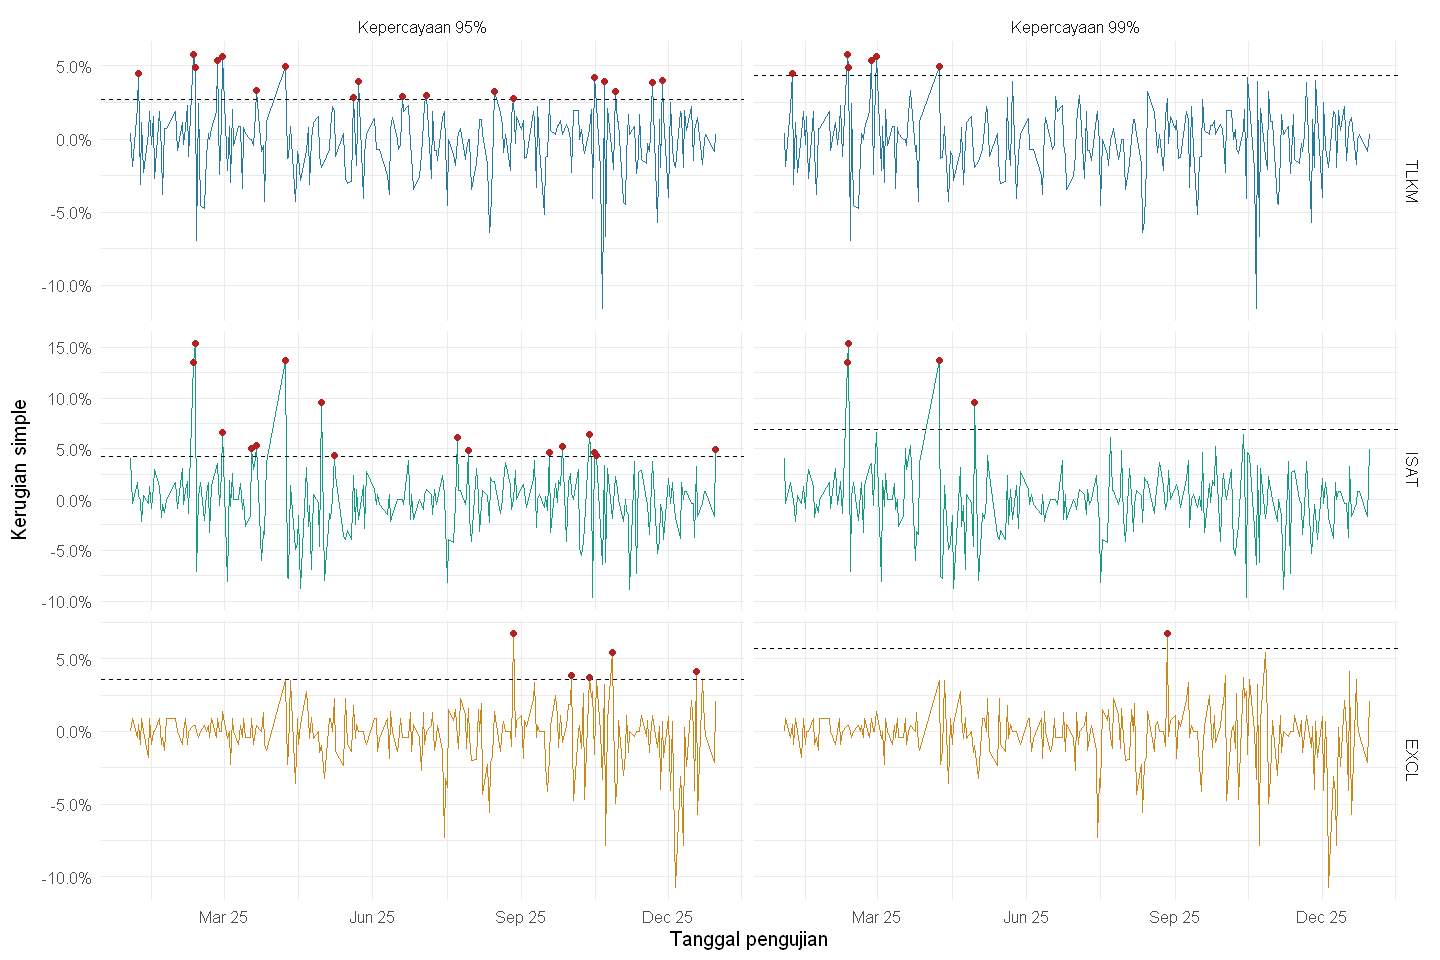

In [157]:
options(repr.plot.height = 8)

plot_daily <- backtest_daily |>
    mutate(Saham = factor(Saham, levels = SAHAM),
           Tingkat = paste0("Kepercayaan ", 100 * Kepercayaan, "%"))
thresholds <- plot_daily |> distinct(Saham, Tingkat, VaR_harian)
ggplot(plot_daily, aes(Tanggal, Kerugian, color = Saham)) +
    geom_line(linewidth = 0.35) +
    geom_hline(data = thresholds, aes(yintercept = VaR_harian),
               color = "black", linetype = "dashed") +
    geom_point(data = filter(plot_daily, Exception == 1), color = "firebrick", size = 1.6) +
    facet_grid(Saham ~ Tingkat, scales = "free_y") + scale_color_manual(values = COLORS) +
    scale_y_continuous(labels = percent) +
    scale_x_date(date_breaks = "3 months", date_labels = "%b %y") +
    labs(x = "Tanggal pengujian", y = "Kerugian simple") + theme(legend.position = "none")

## 11. Referensi

1. Najamuddin, F. F., Herdiani, E. T., & Jaya, A. K. (2024). *Value at Risk Estimation Using Extreme Value Theory Approach in Indonesia Stock Exchange*. BAREKENG, 18(2), 695–706. https://doi.org/10.30598/barekengvol18iss2pp0695-0706
2. Ayuni, N., Rizki, S. W., & Perdana, H. (2020). *Analisis Risiko Portofolio LQ45 Menggunakan Pendekatan Value at Risk Block Maxima-Generalized Extreme Value*. Bimaster, 9(2). https://doi.org/10.26418/bbimst.v9i2.39914
3. Ambarsari, A., Sudarno, & Tarno. (2016). *Perbandingan Pendekatan Generalized Extreme Value dan Generalized Pareto Distribution untuk Perhitungan Value at Risk pada Portofolio Saham*. Jurnal Gaussian, 5(3), 361–371. https://doi.org/10.14710/j.gauss.5.3.361-371
4. Kupiec, P. H. (1995). *Techniques for Verifying the Accuracy of Risk Measurement Models*. Finance and Economics Discussion Series 95-24, Board of Governors of the Federal Reserve System. https://fedinprint.org/item/fedgfe/34596/original
5. Simpson, E. S., & Northrop, P. J. (2026). *Accounting for Missing Data When Modelling Block Maxima*. Environmetrics, 37(2), e70075. https://doi.org/10.1002/env.70075
6. SciPy. *scipy.stats.genextreme*. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.genextreme.html
7. quantmod. *getSymbols*, *Ad*, *Vo*, dan *ROC*. https://cran.r-project.org/web/packages/quantmod/quantmod.pdf

PDF artikel yang tersedia dan catatan penelusuran tersimpan di folder `Referensi/`. Sumber profil emiten dicantumkan pada bagian deskripsi data.